# Deep-Sea Classification: Context Reliance & Depth Degradation
This notebook imports from the project's `.py` modules and runs the full pipeline on Colab's GPU.

# Analysis
Loads saved results from the training pipeline and runs all statistical
analyses: CRS–degradation correlation, baseline comparisons, robustness
checks, bootstrap confidence intervals, and CRS variance analysis.
No GPU required.

In [1]:
# Install any extra packages not on Colab by default
!pip install fathomnet grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=64e23085b268362a1483211c06fc9683cf7856f60b51e926e0dd729e87afba26
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [fathomnet]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/Shareddrives/CV-Project'

import sys, os
sys.path.insert(0, PROJECT_DIR)
os.chdir(PROJECT_DIR)

import importlib
import pandas as pd
import config
import analysis
import extensions

# Load saved results
per_species_df = pd.read_csv(os.path.join(config.RESULTS_DIR, 'results.csv'), index_col='species')

# Reconstruct per-species dicts used by analysis functions
crs_scores   = per_species_df['crs'].dropna().to_dict()
degradation  = per_species_df['degradation'].dropna().to_dict()
shallow_acc  = per_species_df['shallow_acc'].dropna().to_dict()
uniform_crs  = per_species_df['uniform_crs'].dropna().to_dict()
gaussian_crs = per_species_df['gaussian_crs'].dropna().to_dict()

# Load cached predictions
int_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'intervention_predictions.csv'))

all_ic = pd.read_csv(os.path.join(config.RESULTS_DIR, 'image_crs.csv'))
image_crs = {s: all_ic[all_ic['split'] == s].drop(columns='split') for s in ['shallow', 'deep']}

crs_cw = pd.read_csv(os.path.join(config.RESULTS_DIR, 'crs_correct_vs_incorrect.csv'))

Mounted at /content/drive


## CRS vs degradation

In [3]:
# Core hypothesis test - correlation between depth degradation and context relience

# will have to check for a minimum number of test images in deep and shallow
# currently images with 1 test shallow will be weight equally to those with hundereds
# and those with 0 will give crs_score NaN
qualifying = analysis.select_qualifying_species(per_species_df, min_test_n=5)
rho, p_value = analysis.spearman_correlation(crs_scores, degradation, species=qualifying)
print(f'Spearman ρ = {rho:.3f}, p = {p_value:.4f}')

summary = analysis.generate_summary_table(
    crs_scores, degradation, rho, p_value, species=qualifying,
    baselines={'Uniform random': uniform_crs, 'Centre Gaussian': gaussian_crs})
summary.to_csv('results/correlation_summary.csv')
summary.round(3)



139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
Spearman ρ = -0.047, p = 0.5820
Spearman over 139 species
Spearman over 139 species


,n_species,mean_crs,spearman_rho,p_value
method,,,,
Grad-CAM,139,0.533,-0.047,0.582
Uniform random,139,0.788,-0.008,0.927
Centre Gaussian,139,0.608,0.018,0.836


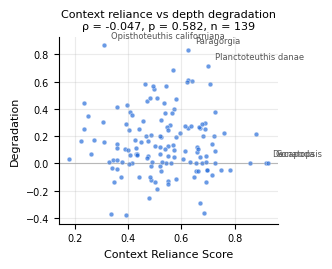

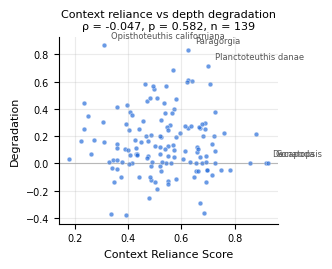

In [4]:
analysis.plot_crs_vs_degradation(crs_scores, degradation, species=qualifying, rho=rho,
                                 p_value=p_value, save_path='results/crs_vs_degradation.png')

### CRS correct vs wrong predictions


,split,n_correct,n_incorrect,median_crs_correct,median_crs_incorrect,p_pooled,n_species_within,median_within_species_diff,p_within
0,shallow,10661,2864,0.4718,0.5378,0.0,97,0.0716,0.0
1,deep,6494,3881,0.5230,0.5995,0.0,93,0.0780,0.0


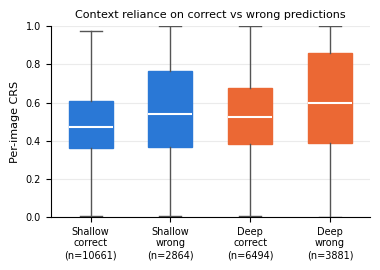

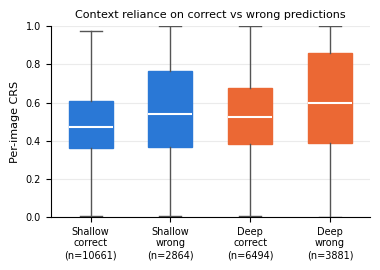

In [5]:
display(crs_cw.round(4))
extensions.plot_crs_correct_vs_incorrect(image_crs, species=qualifying,
                                         save_path='results/crs_correct_vs_wrong.png')

### Checking against baselines

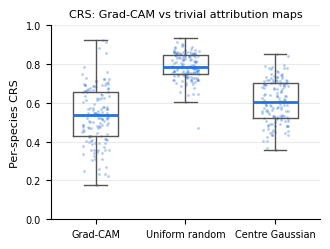

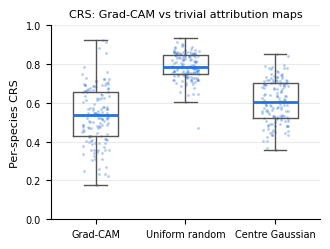

In [6]:
# Checking against baselines
# crs vs organism size (is high crs just because organism is larger in crop?)
analysis.plot_baseline_comparison(crs_scores, uniform_crs, gaussian_crs, species=qualifying,
                                  save_path='results/baseline_crs.png')


/content/drive/Shareddrives/CV-Project/analysis.py:151: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()


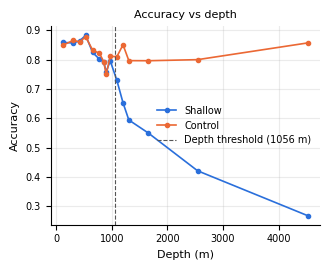

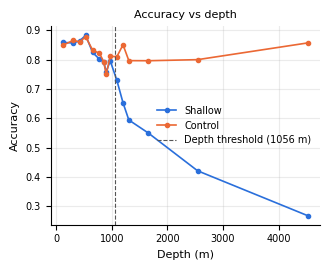

In [7]:
# degradation vs control
# Accuracy vs depth curve for shallow-trained and control models
predictions = pd.read_csv(os.path.join(config.RESULTS_DIR, 'predictions.csv'))
depth_df = pd.read_csv(config.DEPTH_PATH)

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    save_path='results/control_comparison.png')

In [8]:
# Summary table


# TODO: attention map/crs on shallow-only vs control model, deep vs shallow images
# (2x2 grid per species)
# does attribution move to the background in deep images?
# and does the control model attribution stay on the organism?


In [9]:
# 1. Does the result depend on how many test crops a species needs?
for n in [5, 10, 20]:
    q = analysis.select_qualifying_species(per_species_df, min_test_n=n)
    r, p = analysis.spearman_correlation(crs_scores, degradation, species=q)
    print(f"min_test_n={n}: n_species={len(q)}, rho={r:.3f}, p={p:.3f}")

# 2. Species the model barely recognises even in shallow water can't degrade much,
#    which can hide a relationship. Re-run on species it learned reasonably well.
learned = [s for s in qualifying if shallow_acc[s] >= 0.3]
r, p = analysis.spearman_correlation(crs_scores, degradation, species=learned)
print(f"shallow_acc >= 0.3: n_species={len(learned)}, rho={r:.3f}, p={p:.3f}")

139 / 314 species qualify (>= 5 shallow and deep test crops, CRS available)
Spearman over 139 species
min_test_n=5: n_species=139, rho=-0.047, p=0.582
98 / 314 species qualify (>= 10 shallow and deep test crops, CRS available)
Spearman over 98 species
min_test_n=10: n_species=98, rho=0.051, p=0.619
66 / 314 species qualify (>= 20 shallow and deep test crops, CRS available)
Spearman over 66 species
min_test_n=20: n_species=66, rho=-0.067, p=0.594
Spearman over 110 species
shallow_acc >= 0.3: n_species=110, rho=0.036, p=0.712


## Background Intervention Results

shallow_acc  deep_acc  degradation  n_species
model   mode                                                             
shallow Original                  0.592     0.440        0.151        139
        Background greyed         0.240     0.201        0.038        139
        Background blurred        0.433     0.337        0.096        139
        Organism greyed           0.066     0.036        0.029        139
control Original                  0.618     0.670       -0.052        139
        Background greyed         0.269     0.304       -0.036        139
        Background blurred        0.500     0.532       -0.033        139
        Organism greyed           0.054     0.048        0.006        139

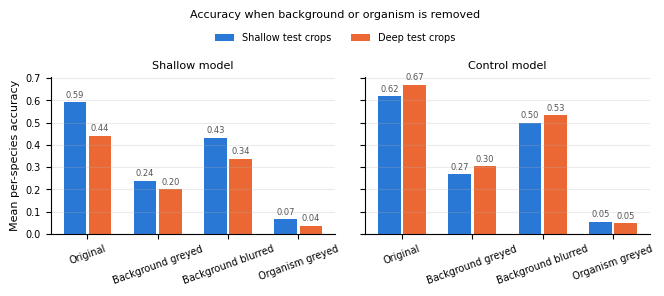

CRS vs accuracy drop (Background greyed): rho = -0.008, p = 0.93, n = 139 species
CRS vs accuracy drop (Background blurred): rho = -0.120, p = 0.161, n = 139 species


In [10]:
importlib.reload(extensions)

int_summary = extensions.intervention_summary(int_preds, species=qualifying)
int_summary.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_summary.csv'))
display(int_summary.round(3))
extensions.plot_intervention_summary(int_summary, save_path='results/intervention_accuracy.png')

# Does greying the background hurt the species Grad-CAM said rely on it?
bg_dep, bg_dep_stats = extensions.background_dependence(int_preds, crs_scores, species=qualifying)




In [11]:
boot = extensions.bootstrap_intervention(int_preds, species=qualifying)
boot.to_csv(os.path.join(config.RESULTS_DIR, 'intervention_bootstrap.csv'), index=False)
display(boot.round(3))


Bootstrap over 139 species, 2000 resamples


,model,mode,metric,estimate,ci_low,ci_high,significant
0,shallow,Background greyed,degradation,0.038,0.015,0.063,True
1,shallow,Background greyed,reduction,0.113,0.076,0.151,True
2,shallow,Background greyed,retention_gap,0.052,0.003,0.104,True
3,control,Background greyed,degradation,-0.036,-0.069,-0.003,True
4,control,Background greyed,reduction,-0.017,-0.054,0.022,False
5,control,Background greyed,retention_gap,0.019,-0.026,0.064,False
6,shallow - control,Background greyed,retention_gap,0.033,-0.021,0.092,False
7,shallow,Background blurred,degradation,0.096,0.066,0.127,True
8,shallow,Background blurred,reduction,0.055,0.026,0.084,True
9,shallow,Background blurred,retention_gap,0.033,-0.018,0.083,False


### Background Swap

Swap decomposition over 139 species, 2000 resamples


,model,metric,estimate,ci_low,ci_high,significant
0,shallow,original_degradation,0.151,0.112,0.190,True
1,shallow,composite_degradation,0.044,0.019,0.068,True
2,shallow,background_effect,-0.007,-0.017,0.003,False
3,shallow,organism_effect,0.051,0.028,0.074,True
4,shallow,compositing_cost,0.292,0.256,0.327,True
5,shallow,background_share,-0.164,-0.696,0.055,False
6,control,original_degradation,-0.052,-0.094,-0.013,True
7,control,composite_degradation,-0.023,-0.055,0.007,False
8,control,background_effect,-0.001,-0.014,0.010,False
9,control,organism_effect,-0.022,-0.049,0.004,False


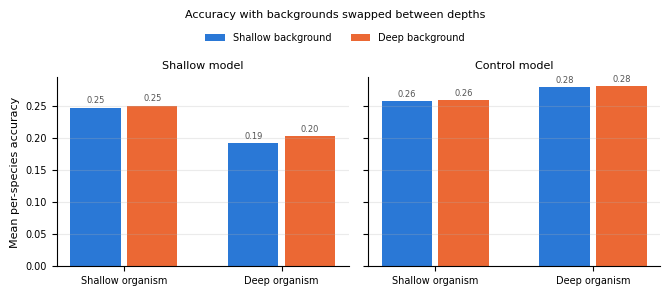

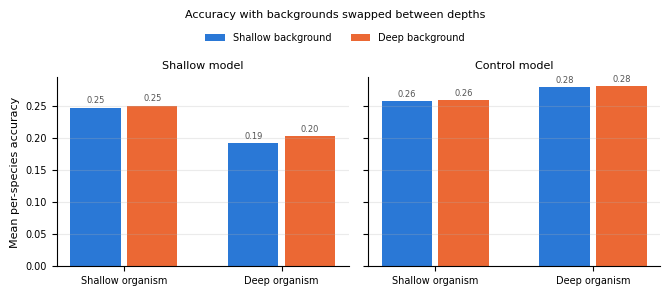

In [12]:
# Background swap: how much of the degradation follows the background vs the organism?
importlib.reload(extensions)
swap_preds = pd.read_csv(os.path.join(config.RESULTS_DIR, 'swap_predictions.csv'))

swap = extensions.swap_decomposition(swap_preds, species=qualifying)
swap.to_csv(os.path.join(config.RESULTS_DIR, 'swap_decomposition.csv'), index=False)
display(swap.round(3))

extensions.plot_swap(swap_preds, species=qualifying, save_path='results/background_swap.png')

### Within-species CRS variance vs degradation
The image-level analysis shows CRS predicts errors within species, but species-level mean CRS doesn't predict degradation. Does CRS *variance* bridge that gap? Species with inconsistent context reliance (high variance) may be more vulnerable to distribution shift than species with stable CRS.

CRS std vs degradation: rho = -0.128, p = 0.134, n = 139 species
CRS iqr vs degradation: rho = 0.003, p = 0.971, n = 139 species
CRS mean vs degradation: rho = -0.047, p = 0.582, n = 139 species


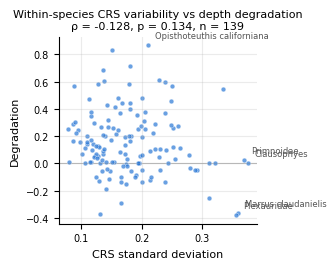

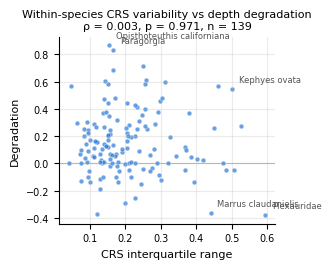

,mean,std,iqr,count,degradation
count,139.000,139.000,139.000,139.000,139.000
mean,0.533,0.178,0.209,97.302,0.151
std,0.147,0.064,0.111,155.019,0.235
min,0.177,0.077,0.041,5.000,-0.381
25%,0.428,0.129,0.135,13.000,0.000
50%,0.536,0.167,0.177,29.000,0.112
75%,0.655,0.211,0.256,111.000,0.274
max,0.925,0.375,0.595,755.000,0.867


In [13]:
importlib.reload(extensions)

# Per-species CRS std, IQR, and mean vs degradation (shallow image CRS)
var_df, var_stats = extensions.crs_variance_analysis(
    image_crs['shallow'], degradation, species=qualifying)

# Scatter plot for CRS std
rho_std, p_std, n_std = var_stats['std']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='std', rho=rho_std, p_value=p_std,
    save_path='results/crs_variance_vs_degradation.png')

# Also show IQR (more robust to outliers)
rho_iqr, p_iqr, n_iqr = var_stats['iqr']
extensions.plot_crs_variance_vs_degradation(
    var_df, metric='iqr', rho=rho_iqr, p_value=p_iqr)

display(var_df[['mean', 'std', 'iqr', 'count', 'degradation']].describe().round(3))

### CRS normalised for mask size
CRS measures the fraction of Grad-CAM activation outside the organism mask.
Species with smaller masks will mechanically score higher even if the model
focuses on the organism, because more area lies outside the mask.

Normalised CRS = raw CRS / uniform CRS.  The uniform baseline CRS for a
species equals 1 − mean mask coverage (what CRS would be under random
attribution), so dividing scales out the geometric effect.  A value of 1
means the model is no more context-reliant than chance; above 1 means
genuinely reliant on background.

Mask coverage vs CRS: ρ = -0.694, p = 2.54e-21, n = 139
Raw CRS vs degradation: ρ = -0.047, p = 0.582, n = 139
Normalised CRS vs degradation: ρ = -0.080, p = 0.348, n = 139


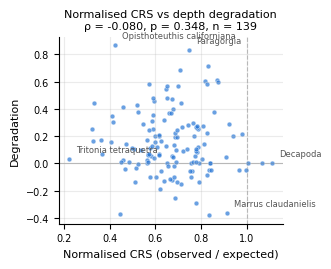

,crs,mask_coverage,normalised_crs,degradation
count,139.000,139.000,139.000,139.000
mean,0.533,0.212,0.671,0.151
std,0.147,0.069,0.158,0.235
min,0.177,0.067,0.222,-0.381
25%,0.428,0.155,0.576,0.000
50%,0.536,0.217,0.675,0.112
75%,0.655,0.253,0.780,0.274
max,0.925,0.532,1.113,0.867


In [14]:
importlib.reload(extensions)

# Uses uniform_crs as proxy for mask coverage (uniform CRS = 1 - coverage)
adj_df, adj_stats = extensions.crs_mask_size_analysis(
    crs_scores, uniform_crs, degradation, species=qualifying)

# Scatter: normalised CRS vs degradation
rho_adj, p_adj, n_adj = adj_stats['normalised_crs_vs_degradation']
extensions.plot_normalised_crs_vs_degradation(
    adj_df, rho=rho_adj, p_value=p_adj,
    save_path='results/normalised_crs_vs_degradation.png')

display(adj_df[['crs', 'mask_coverage', 'normalised_crs', 'degradation']].describe().round(3))

### Is degradation driven by context reliance?
For species whose accuracy degrades at depth, is this because they relied on
background context in shallow water? If so, removing the background should
shrink the shallow-to-deep accuracy gap for degrading species more than for
non-degrading ones.

Background reliance vs degradation: ρ = 0.380, p = 3.87e-06, n = 139
Degradation reduction vs degradation: ρ = 0.765, p = 5.72e-28, n = 139
Background reliance vs degradation: ρ = 0.274, p = 0.00111, n = 139
Degradation reduction vs degradation: ρ = 0.522, p = 4.24e-11, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:767: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby("bin_mid")[orig_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:768: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  edit = sub.groupby("bin_mid")[edit_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:767: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby

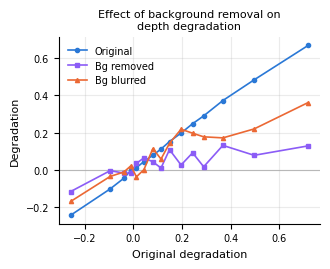

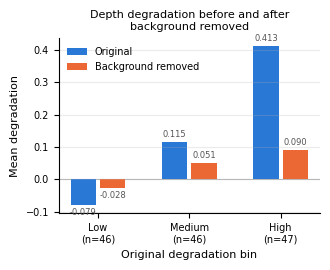

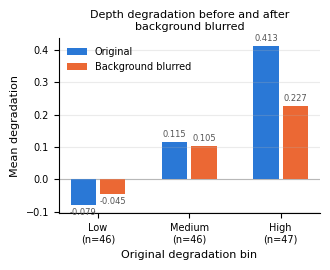


--- Control model ---
Background reliance vs degradation: ρ = 0.166, p = 0.0502, n = 139
Degradation reduction vs degradation: ρ = 0.212, p = 0.0124, n = 139
Background reliance vs degradation: ρ = 0.021, p = 0.802, n = 139
Degradation reduction vs degradation: ρ = 0.180, p = 0.0344, n = 139


/content/drive/Shareddrives/CV-Project/extensions.py:767: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby("bin_mid")[orig_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:768: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  edit = sub.groupby("bin_mid")[edit_col].mean()
/content/drive/Shareddrives/CV-Project/extensions.py:767: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  orig = sub.groupby

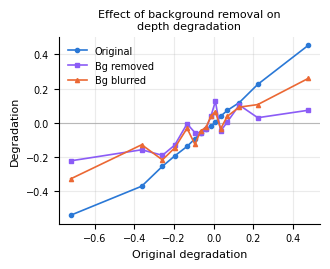

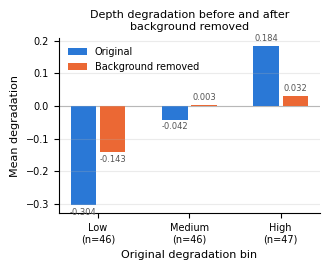

/content/drive/Shareddrives/CV-Project/analysis.py:151: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:151: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:151: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return df.groupby(bin_col)["

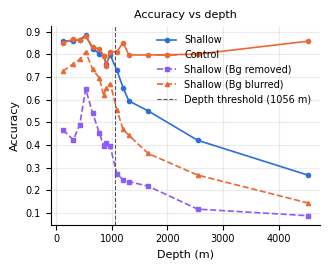

/content/drive/Shareddrives/CV-Project/analysis.py:152: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col, "species"])["correct"].mean()
/content/drive/Shareddrives/CV-Project/analysis.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return per.groupby(bin_col).mean()
/content/drive/Shareddrives/CV-Project/analysis.py:152: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby([bin_col,

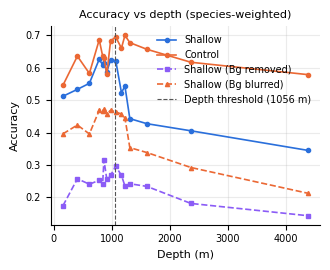

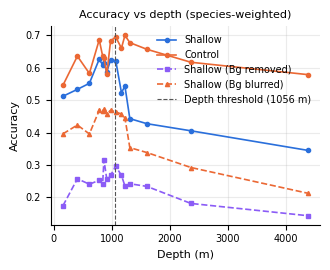

In [15]:
importlib.reload(extensions)
importlib.reload(analysis)


# Shallow model — per-species degradation before and after interventions
ctx_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='grey_bg')
ctx_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='shallow', mode='blur_bg')


# Continuous line plot — shallow model
extensions.plot_degradation_before_after(
    ctx_df_grey, df_blur=ctx_df_blur,
    save_path='results/degradation_before_after.png')

# Binned bar charts
extensions.plot_degradation_bar(
    ctx_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey.png')

extensions.plot_degradation_bar(
    ctx_df_blur, mode_label='background blurred',
    save_path='results/degradation_bar_blur.png')

# --- Control model (negative control for regression to the mean) ---
print('\n--- Control model ---')
ctrl_df_grey, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='grey_bg')
ctrl_df_blur, _ = extensions.degradation_context_analysis(
    int_preds, degradation, species=qualifying, model='control', mode='blur_bg')

extensions.plot_degradation_before_after(
    ctrl_df_grey, df_blur=ctrl_df_blur,
    save_path='results/degradation_before_after_control.png')

extensions.plot_degradation_bar(
    ctrl_df_grey, mode_label='background removed',
    save_path='results/degradation_bar_grey_control.png')

# Accuracy vs depth

analysis.plot_accuracy_vs_depth(
    predictions, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=int_preds, int_modes=['grey_bg', 'blur_bg'],
    save_path='results/accuracy_vs_depth_bgintervention.png')

# Species-weighted accuracy vs depth — every species counts equally

# Filter to qualifying species for fair species-weighted comparison
qual_preds = predictions[predictions['species'].isin(qualifying)]
qual_int = int_preds[int_preds['species'].isin(qualifying)]

analysis.plot_accuracy_vs_depth(
    qual_preds, depth_df,
    depth_threshold=config.DEPTH_SHALLOW_MAX,
    int_preds=qual_int, int_modes=['grey_bg', 'blur_bg'],
    species_weighted=True,
    save_path='results/accuracy_vs_depth_species_weighted.png')